# ДЗ 1. Книжный рекомендательный сервис на goodbooks-10k

Сделал EDA, популярное, контентную модель на TF-IDF, item-based CF, SVD, посчитал метрики и в конце собрал простой гибрид. Модели и метрики лежат в `src/`, тут только запуск и комментарии.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(str(Path.cwd()))
from src.data import DATA_DIR, load_data, clean_book_tags, train_test_split_by_user, to_csr
from src.models import (PopularityRecommender, ContentRecommender, ItemBasedCF,
                        SVDRecommender, HybridRecommender, user_means)
from src.metrics import rmse, precision_at_k, recall_at_k, ndcg_at_k, evaluate_topn

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 70)
SEED = 42

## 0. Данные

При загрузке убрал повторные оценки (в этой версии датасета они есть) и перевёл теги с goodreads_book_id на обычный id книги, иначе они не стыкуются с ratings.

In [2]:
raw_ratings = pd.read_csv(DATA_DIR / "ratings.csv")
ratings, books, tags, book_tags = load_data()
to_read = pd.read_csv(DATA_DIR / "to_read.csv")

n_users, n_items = ratings["user_id"].max(), books["id"].max()
titles = books.set_index("id")["title"]
authors = books.set_index("id")["authors"]


def with_titles(df, col="book_id"):
    out = df.copy()
    out.insert(1, "title", out[col].map(titles).values)
    out.insert(2, "authors", out[col].map(authors).values)
    return out


pd.Series({
    "оценок в файле": len(raw_ratings),
    "повторных оценок удалено": len(raw_ratings) - len(ratings),
    "оценок после чистки": len(ratings),
    "пользователей": n_users,
    "книг": n_items,
    "заполненность матрицы, %": round(100 * len(ratings) / (n_users * n_items), 3),
    "тегов": len(tags),
    "связей книга-тег": len(book_tags),
}).to_frame("значение")

,значение
оценок в файле,981756.000
повторных оценок удалено,2278.000
оценок после чистки,979478.000
пользователей,53424.000
книг,10000.000
"заполненность матрицы, %",0.183
тегов,34252.000
связей книга-тег,999898.000


## 1. EDA

### Оценки

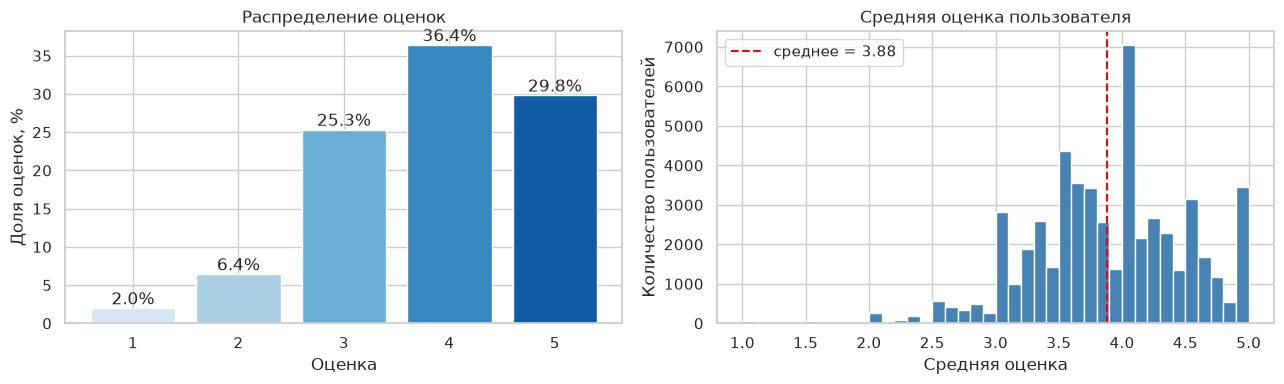

Средняя оценка: 3.86, доля оценок >= 4: 66.2%


In [3]:
share = ratings["rating"].value_counts(normalize=True).sort_index() * 100
u_mean = ratings.groupby("user_id")["rating"].mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(share.index, share.values, color=sns.color_palette("Blues", 5))
for x, y in share.items():
    axes[0].text(x, y + 0.5, f"{y:.1f}%", ha="center")
axes[0].set(title="Распределение оценок", xlabel="Оценка", ylabel="Доля оценок, %")

axes[1].hist(u_mean, bins=40, color="steelblue")
axes[1].axvline(u_mean.mean(), color="red", ls="--", label=f"среднее = {u_mean.mean():.2f}")
axes[1].set(title="Средняя оценка пользователя", xlabel="Средняя оценка", ylabel="Количество пользователей")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Средняя оценка: {ratings['rating'].mean():.2f}, доля оценок >= 4: {share.loc[[4, 5]].sum():.1f}%")

Да, оценки смещены вверх: 4 и 5 это примерно две трети, единиц почти нет. Люди в основном оценивают то, что сами выбрали. Поэтому дальше релевантной считаю оценку от 4, тройка тут скорее "нормально".

### Активность пользователей

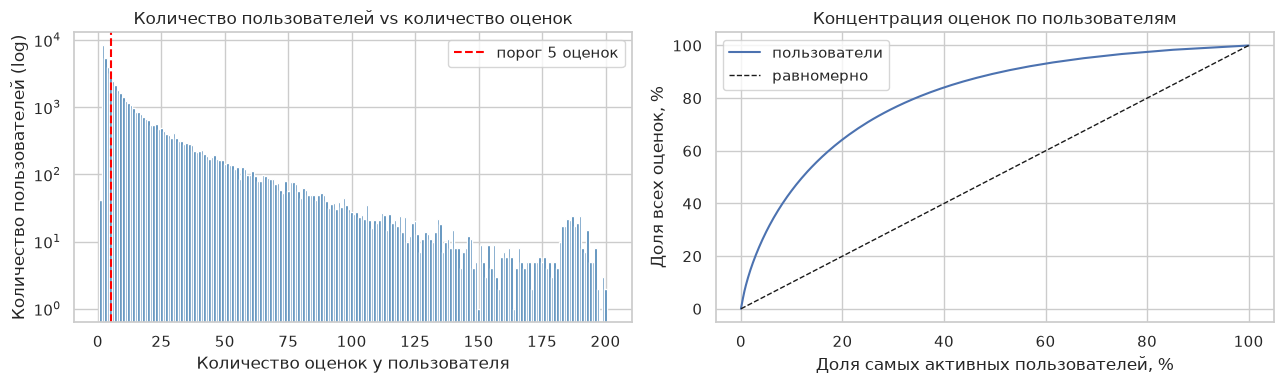

,пользователей,"доля пользователей, %","доля оценок, %"
2-4 (холодные),17723,33.2,5.0
5-20,21688,40.6,22.8
21-100,12805,24.0,55.6
101+,1166,2.2,16.6


In [4]:
user_cnt = ratings.groupby("user_id").size()
dist = user_cnt.value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(dist.index, dist.values, width=1.0, color="steelblue")
axes[0].axvline(5, color="red", ls="--", label="порог 5 оценок")
axes[0].set_yscale("log")
axes[0].set(title="Количество пользователей vs количество оценок",
            xlabel="Количество оценок у пользователя", ylabel="Количество пользователей (log)")
axes[0].legend()

s = np.sort(user_cnt.values)[::-1]
x = np.arange(1, len(s) + 1) / len(s) * 100
axes[1].plot(x, np.cumsum(s) / s.sum() * 100, label="пользователи")
axes[1].plot([0, 100], [0, 100], "k--", lw=1, label="равномерно")
axes[1].set(title="Концентрация оценок по пользователям",
            xlabel="Доля самых активных пользователей, %", ylabel="Доля всех оценок, %")
axes[1].legend()
plt.tight_layout()
plt.show()

groups = pd.cut(user_cnt, [1, 4, 20, 100, 1000], labels=["2-4 (холодные)", "5-20", "21-100", "101+"])
pd.DataFrame({
    "пользователей": groups.value_counts().sort_index(),
    "доля пользователей, %": (groups.value_counts(normalize=True).sort_index() * 100).round(1),
    "доля оценок, %": (user_cnt.groupby(groups, observed=True).sum() / len(ratings) * 100).round(1),
})

In [5]:
top10 = int(len(s) * 0.1)
print(f"Медиана оценок на пользователя: {user_cnt.median():.0f}, максимум: {user_cnt.max()}")
print(f"Топ-10% пользователей дают {s[:top10].sum() / s.sum() * 100:.1f}% оценок")
print("Самые активные пользователи:")
user_cnt.nlargest(5).rename("оценок").to_frame()

Медиана оценок на пользователя: 8, максимум: 200
Топ-10% пользователей дают 44.9% оценок
Самые активные пользователи:


,оценок
user_id,
12874,200
30944,200
12381,199
28158,199
52036,199


У трети пользователей меньше 5 оценок, для них персональные рекомендации почти не построить, это холодный старт. Самые активные 10% дают почти половину всех оценок, так что модели будут в основном учиться на них. Сверху активность обрезана на 200 оценках.

### Популярность книг

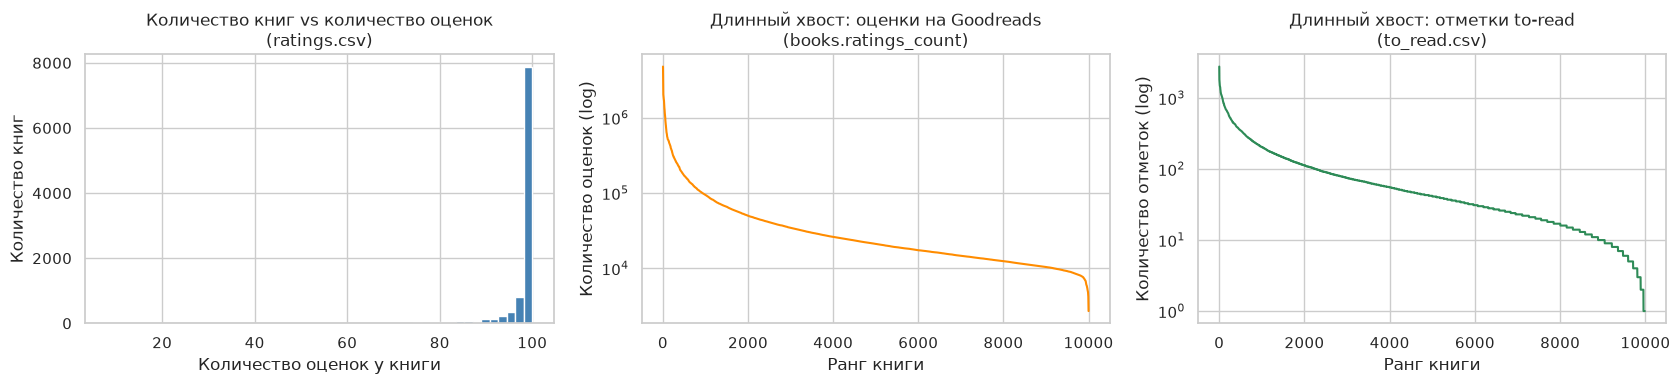

ratings.csv: оценок на книгу min=8, медиана=100, max=100
Goodreads: топ-1% книг собирают 23.4% оценок
to_read: топ-1% книг собирают 13.0% отметок


In [6]:
book_cnt = ratings.groupby("book_id").size()
gr_sorted = books["ratings_count"].sort_values(ascending=False).values
tr_sorted = to_read.groupby("book_id").size().sort_values(ascending=False).values

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].hist(book_cnt, bins=50, color="steelblue")
axes[0].set(title="Количество книг vs количество оценок\n(ratings.csv)",
            xlabel="Количество оценок у книги", ylabel="Количество книг")

axes[1].plot(np.arange(1, len(gr_sorted) + 1), gr_sorted, color="darkorange")
axes[1].set_yscale("log")
axes[1].set(title="Длинный хвост: оценки на Goodreads\n(books.ratings_count)",
            xlabel="Ранг книги", ylabel="Количество оценок (log)")

axes[2].plot(np.arange(1, len(tr_sorted) + 1), tr_sorted, color="seagreen")
axes[2].set_yscale("log")
axes[2].set(title="Длинный хвост: отметки to-read\n(to_read.csv)",
            xlabel="Ранг книги", ylabel="Количество отметок (log)")
plt.tight_layout()
plt.show()

top1 = int(len(gr_sorted) * 0.01)
print(f"ratings.csv: оценок на книгу min={book_cnt.min()}, медиана={book_cnt.median():.0f}, max={book_cnt.max()}")
print(f"Goodreads: топ-1% книг собирают {gr_sorted[:top1].sum() / gr_sorted.sum() * 100:.1f}% оценок")
print(f"to_read: топ-1% книг собирают {tr_sorted[:top1].sum() / tr_sorted.sum() * 100:.1f}% отметок")

In [7]:
with_titles(books.nlargest(10, "ratings_count")[["id", "ratings_count", "average_rating"]]
            .rename(columns={"id": "book_id"}))

,book_id,title,authors,ratings_count,average_rating
0,1,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,4780653,4.34
1,2,"Harry Potter and the Sorcerer's Stone (Harry Potter, #1)","J.K. Rowling, Mary GrandPré",4602479,4.44
2,3,"Twilight (Twilight, #1)",Stephenie Meyer,3866839,3.57
3,4,To Kill a Mockingbird,Harper Lee,3198671,4.25
4,5,The Great Gatsby,F. Scott Fitzgerald,2683664,3.89
5,6,The Fault in Our Stars,John Green,2346404,4.26
6,7,The Hobbit,J.R.R. Tolkien,2071616,4.25
7,8,The Catcher in the Rye,J.D. Salinger,2044241,3.79
9,10,Pride and Prejudice,Jane Austen,2035490,4.24
8,9,"Angels & Demons (Robert Langdon, #1)",Dan Brown,2001311,3.85


Неожиданно: в ratings.csv почти у всех книг ровно около 100 оценок. Видимо, датасет так собирали, и популярность внутри ratings просто срезана. Настоящий длинный хвост видно по ratings_count из books.csv и по to_read: там 1% книг собирает заметную часть всех оценок. Самые популярные книги ожидаемые: Голодные игры, Гарри Поттер, Сумерки.

Получается, что по ratings популярные книги ничем не выделяются, и топ популярного, скорее всего, будет плохо угадывать тест.

### Теги

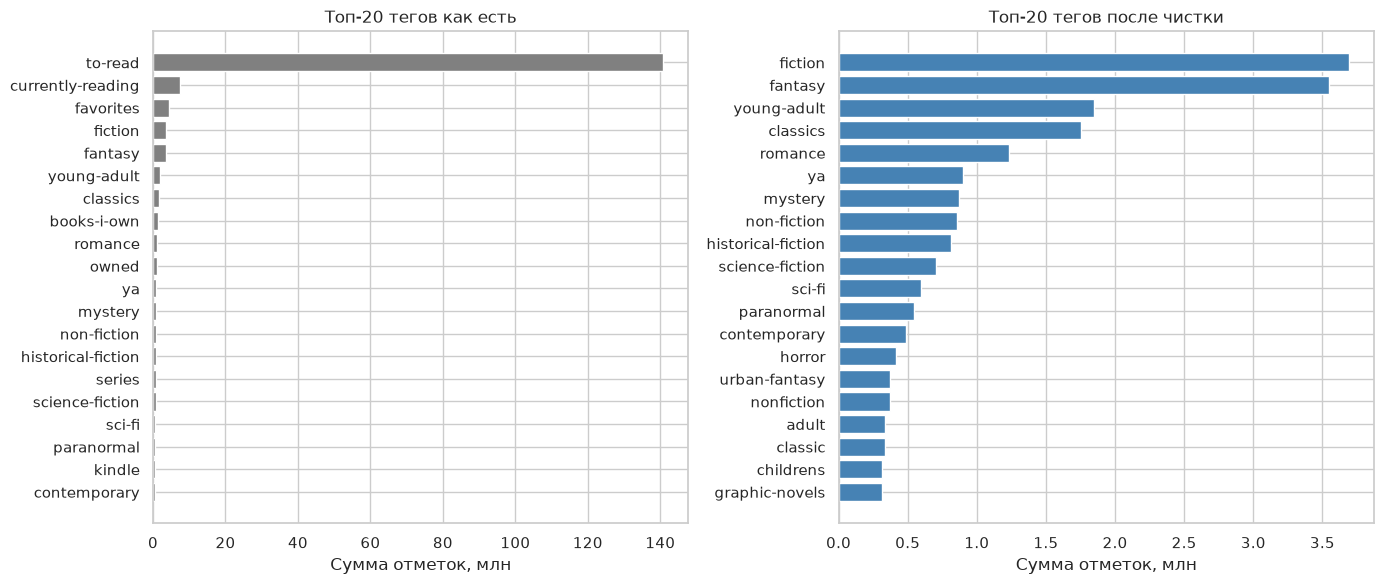

Уникальных тегов: было 34250, после чистки 3130


In [8]:
clean_tags = clean_book_tags(book_tags, min_books=20)
raw_top = book_tags.groupby("tag_name")["count"].sum().nlargest(20)
clean_top = clean_tags.groupby("tag_name")["count"].sum().nlargest(20)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(raw_top.index[::-1], raw_top.values[::-1] / 1e6, color="gray")
axes[0].set(title="Топ-20 тегов как есть", xlabel="Сумма отметок, млн")
axes[1].barh(clean_top.index[::-1], clean_top.values[::-1] / 1e6, color="steelblue")
axes[1].set(title="Топ-20 тегов после чистки", xlabel="Сумма отметок, млн")
plt.tight_layout()
plt.show()

print(f"Уникальных тегов: было {book_tags['tag_id'].nunique()}, после чистки {clean_tags['tag_id'].nunique()}")

Сверху сырого топа служебные полки вроде to-read, favorites, owned, про содержание книги они ничего не говорят. Убрал их регуляркой и заодно выкинул теги, которые есть меньше чем у 20 книг. После этого остаются нормальные жанры. Остались синонимы (sci-fi и science-fiction, ya и young-adult), но с ними уже не стал возиться.

### Что видно по данным

Матрица заполнена на 0.18%, треть пользователей холодные, оценки смещены вверх. Длинный хвост популярности есть в реальности (Goodreads, to-read), но в ratings.csv срезан. Времени оценок нет, теги шумные.

## 2. Разбиение и базовые модели

Времени нет, поэтому у каждого пользователя с 5 и больше оценками случайно откладываю 20% в тест. Остальные пользователи целиком идут в train. Параметры подбирал на валидации, которую так же отрезал от train, а тест трогал только для итоговой таблицы.

In [9]:
train, test = train_test_split_by_user(ratings, test_size=0.2, min_ratings=5, seed=SEED)
train_in, val = train_test_split_by_user(train, test_size=0.2, min_ratings=5, seed=SEED + 1)

R_train = to_csr(train, n_users, n_items)
R_in = to_csr(train_in, n_users, n_items)

rng = np.random.default_rng(SEED)
val_users = rng.choice(np.unique(val.loc[val["rating"] >= 4, "user_id"].values - 1), 5000, replace=False)
test_users = np.unique(test.loc[test["rating"] >= 4, "user_id"].values - 1)

pd.DataFrame({
    "оценок": [len(train), len(test), len(train_in), len(val)],
    "пользователей": [train.user_id.nunique(), test.user_id.nunique(), train_in.user_id.nunique(), val.user_id.nunique()],
}, index=["train", "test", "train_in (подбор)", "val (подбор)"])

,оценок,пользователей
train,806226,53424
test,173252,35659
train_in (подбор),669366,53424
val (подбор),136860,32439


In [10]:
print("Пользователи test без истории в train:", len(set(test.user_id) - set(train.user_id)))
print("Пересечение train и test по парам:", len(train.merge(test, on=["user_id", "book_id"])))
print("Пользователей для оценки top-N на test:", len(test_users))

Пользователи test без истории в train: 0
Пересечение train и test по парам: 0
Пользователей для оценки top-N на test: 30440


### Популярное

Средний рейтинг книги по train. Книги, у которых меньше 50 оценок, не беру (в среднем у книги в train около 80 оценок).

In [11]:
pop = PopularityRecommender(min_ratings=50).fit(R_train)
with_titles(pop.top_books(10))

,book_id,title,authors,mean_rating,n_ratings
0,6361,There's Treasure Everywhere: A Calvin and Hobbes Collection,Bill Watterson,4.807,83
1,7947,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem",4.802,81
2,6920,The Indispensable Calvin and Hobbes,Bill Watterson,4.793,82
3,5207,The Days Are Just Packed: A Calvin and Hobbes Collection,Bill Watterson,4.790,81
4,9806,"One Piece, Volume 38: Rocketman!! (One Piece, #38)",Eiichirō Oda,4.787,61
5,3275,"Harry Potter Boxed Set, Books 1-5 (Harry Potter, #1-5)","J.K. Rowling, Mary GrandPré",4.779,86
6,8978,The Revenge of the Baby-Sat,Bill Watterson,4.773,88
7,9566,Attack of the Deranged Mutant Killer Monster Snow Goons,Bill Watterson,4.767,86
8,8109,"The Absolute Sandman, Volume One","Neil Gaiman, Mike Dringenberg, Chris Bachalo, Michael Zulli, Kelly...",4.757,74
9,4483,It's a Magical World: A Calvin and Hobbes Collection,Bill Watterson,4.750,80


Сверху Calvin and Hobbes, подарочные издания и Библия. Высокий средний у них, потому что их ставят в основном фанаты. Для нового пользователя такой список выглядит странно.

### Контентная модель

Профиль книги: original_title (если пусто, то title) и 20 самых частых тегов. Тег склеиваю в одно слово, чтобы science-fiction не разваливался на два.

In [12]:
content = ContentRecommender(top_tags=20).fit(books, clean_tags, R_train)
print("TF-IDF матрица:", content.X.shape, f"заполненность {content.X.nnz / np.prod(content.X.shape) * 100:.2f}%")
content.profiles.head(3).to_frame("профиль")

TF-IDF матрица: (10000, 5203) заполненность 0.42%


,профиль
1,The Hunger Games young_adult fiction dystopian dystopia fantasy ya...
2,Harry Potter and the Philosopher's Stone fantasy young_adult ficti...
3,Twilight young_adult fantasy vampires ya fiction paranormal vampir...


In [13]:
for bid in [1, 2, 10, 39]:
    print(f"Похожие на: {titles[bid]}")
    display(content.get_similar_books(bid, N=5))

Похожие на: The Hunger Games (The Hunger Games, #1)


,book_id,title,similarity
0,1820,"Hunger (Gone, #2)",0.778
1,20,"Mockingjay (The Hunger Games, #3)",0.762
2,507,"The Hunger Games Trilogy Boxset (The Hunger Games, #1-3)",0.743
3,259,"The Scorch Trials (Maze Runner, #2)",0.670
4,17,"Catching Fire (The Hunger Games, #2)",0.615


Похожие на: Harry Potter and the Sorcerer's Stone (Harry Potter, #1)


,book_id,title,similarity
0,24,"Harry Potter and the Goblet of Fire (Harry Potter, #4)",0.881
1,18,"Harry Potter and the Prisoner of Azkaban (Harry Potter, #3)",0.844
2,23,"Harry Potter and the Chamber of Secrets (Harry Potter, #2)",0.795
3,25,"Harry Potter and the Deathly Hallows (Harry Potter, #7)",0.767
4,27,"Harry Potter and the Half-Blood Prince (Harry Potter, #6)",0.721


Похожие на: Pride and Prejudice


,book_id,title,similarity
0,63,Wuthering Heights,0.602
1,171,Emma,0.539
2,230,Persuasion,0.539
3,471,Mansfield Park,0.502
4,1039,"Pride and Prejudice and Zombies (Pride and Prejudice and Zombies, #1)",0.478


Похожие на: A Game of Thrones (A Song of Ice and Fire, #1)


,book_id,title,similarity
0,135,"A Storm of Swords (A Song of Ice and Fire, #3)",0.712
1,188,"A Dance with Dragons (A Song of Ice and Fire, #5)",0.686
2,110,"A Clash of Kings (A Song of Ice and Fire, #2)",0.674
3,165,"A Feast for Crows (A Song of Ice and Fire, #4)",0.660
4,3282,"A Game of Thrones: The Graphic Novel, Vol. 1",0.642


Выглядит нормально: к Голодным играм подтягиваются другие подростковые антиутопии, к Остин другие классические романы. Но часто модель просто советует остальные книги той же серии, а их человек и сам найдёт.

## 3. Item-based CF

Матрица пользователь x книга с оценками, храню в csr_matrix.

In [14]:
dense_mb = n_users * n_items * 4 / 1024**2
sparse_mb = (R_train.data.nbytes + R_train.indices.nbytes + R_train.indptr.nbytes) / 1024**2
print(f"Размер: {R_train.shape}, ненулевых: {R_train.nnz}, заполненность: {R_train.nnz / np.prod(R_train.shape) * 100:.3f}%")
print(f"Плотная матрица float32: {dense_mb:.0f} МБ, разреженная CSR: {sparse_mb:.1f} МБ")

Размер: (53424, 10000), ненулевых: 806226, заполненность: 0.151%
Плотная матрица float32: 2038 МБ, разреженная CSR: 6.4 МБ


Схожесть книг: adjusted cosine (косинус после вычитания среднего пользователя) со штрафом за малое число общих читателей. Храню top-k соседей, считаю кусками по 1000 книг.

Прогноз оценки: взвешенное среднее оценок пользователя по соседям книги, если соседей нет, то его средняя. Для топ-N беру сумму схожестей с понравившимися книгами (оценка от 4), так работает лучше, чем сортировка по прогнозу.

In [15]:
rows = []
for k in [20, 50, 100]:
    m = ItemBasedCF(k=k).fit(R_in)
    pred = m.predict(val["user_id"], val["book_id"])
    res = evaluate_topn(m, R_in, val, ks=(10,), users=val_users)
    rows.append({"k": k, "RMSE": rmse(val["rating"], pred), "доля прогнозов по соседям": m.last_coverage,
                 "nDCG@10": res["nDCG@10"], "Recall@10": res["Recall@10"]})
icf_tuning = pd.DataFrame(rows).set_index("k").round(4)
icf_tuning

,RMSE,доля прогнозов по соседям,nDCG@10,Recall@10
k,,,,
20,0.8876,0.6179,0.1704,0.2141
50,0.8938,0.7213,0.1697,0.2125
100,0.8975,0.7951,0.1695,0.2126


In [16]:
best_k_icf = int(icf_tuning["nDCG@10"].idxmax())
item_cf = ItemBasedCF(k=best_k_icf).fit(R_train)
print(f"k = {best_k_icf}, связей в матрице схожести: {item_cf.S.nnz}")

print(f"Соседи по CF для: {titles[2]}")
with_titles(item_cf.similar_books(2, N=5))

k = 20, связей в матрице схожести: 199980
Соседи по CF для: Harry Potter and the Sorcerer's Stone (Harry Potter, #1)


,book_id,title,authors,similarity
0,18,"Harry Potter and the Prisoner of Azkaban (Harry Potter, #3)","J.K. Rowling, Mary GrandPré, Rufus Beck",0.367
1,23,"Harry Potter and the Chamber of Secrets (Harry Potter, #2)","J.K. Rowling, Mary GrandPré",0.328
2,10,Pride and Prejudice,Jane Austen,0.221
3,21,"Harry Potter and the Order of the Phoenix (Harry Potter, #5)","J.K. Rowling, Mary GrandPré",0.221
4,25,"Harry Potter and the Deathly Hallows (Harry Potter, #7)","J.K. Rowling, Mary GrandPré",0.213


Среди соседей Гарри Поттера оказалась Гордость и предубеждение. CF смотрит не на жанр, а на то, что читают одни и те же люди.

In [17]:
# пример прогноза для одного пользователя из теста
uid = test["user_id"].value_counts().index[100]
sample = test[test["user_id"] == uid].head(8).copy()
sample["прогноз Item-CF"] = item_cf.predict(sample["user_id"], sample["book_id"]).round(2)
print(f"Пользователь {uid}, оценок в train: {R_train[uid - 1].nnz}, средняя: {user_means(R_train)[uid - 1]:.2f}")
with_titles(sample[["book_id", "rating", "прогноз Item-CF"]])

Пользователь 33716, оценок в train: 149, средняя: 3.68


,book_id,title,authors,rating,прогноз Item-CF
62,3,"Twilight (Twilight, #1)",Stephenie Meyer,3,3.75
80,4,To Kill a Mockingbird,Harper Lee,4,4.29
261,13,1984,"George Orwell, Erich Fromm, Celâl Üster",4,3.96
279,14,Animal Farm,George Orwell,3,3.81
677,34,"Fifty Shades of Grey (Fifty Shades, #1)",E.L. James,1,3.42
1286,64,My Sister's Keeper,Jodi Picoult,2,4.00
1557,78,"The Devil Wears Prada (The Devil Wears Prada, #1)",Lauren Weisberger,3,2.84
1717,87,Night (The Night Trilogy #1),"Elie Wiesel, Marion Wiesel",4,4.25


### Про сложность

В лоб O(I² · U) по времени и O(I²) по памяти, для 10k книг это 10⁸ пар. На разреженной матрице стоимость определяется числом совместных оценок. Прогноз для пользователя O(история · k).

Сделано: разреженные матрицы, расчёт кусками, только top-k соседей. Для больших данных ещё: редкий пересчёт схожестей, приближённый поиск соседей (Annoy, FAISS, HNSW), Spark.

## 4. SVD

Сначала как в примере из курса: вычитаю среднее пользователя, пропуски нули, svds, потом прибавляю среднее обратно и обрезаю до [1, 5]. Число факторов выбираю по RMSE на валидации.

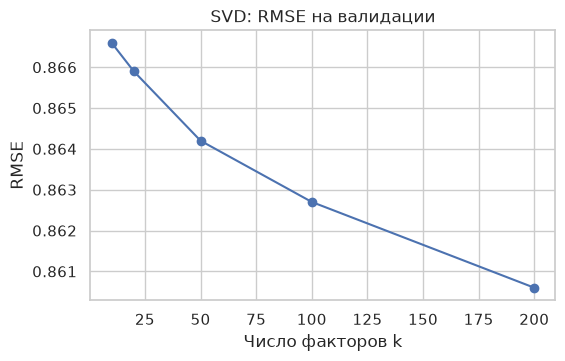

,RMSE val
k,
10,0.8666
20,0.8659
50,0.8642
100,0.8627
200,0.8606


In [18]:
rows = []
for k in [10, 20, 50, 100, 200]:
    m = SVDRecommender(k=k).fit(R_in)
    rows.append({"k": k, "RMSE val": rmse(val["rating"], m.predict(val["user_id"], val["book_id"]))})
    del m
svd_tuning = pd.DataFrame(rows).set_index("k").round(4)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(svd_tuning.index, svd_tuning["RMSE val"], "o-")
ax.set(title="SVD: RMSE на валидации", xlabel="Число факторов k", ylabel="RMSE")
plt.show()
svd_tuning

In [19]:
best_k_svd = int(svd_tuning["RMSE val"].idxmin())
svd_exp = SVDRecommender(k=best_k_svd).fit(R_train)

global_mean = train["rating"].mean()
um = user_means(R_train)
item_mean = np.asarray(R_train.sum(axis=0)).ravel() / np.maximum(np.diff(R_train.tocsc().indptr), 1)
rmse_table = pd.Series({
    "Глобальное среднее": rmse(test["rating"], np.full(len(test), global_mean)),
    "Среднее книги": rmse(test["rating"], item_mean[test["book_id"] - 1]),
    "Среднее пользователя": rmse(test["rating"], um[test["user_id"] - 1]),
    f"Item-based CF (k={best_k_icf})": rmse(test["rating"], item_cf.predict(test["user_id"], test["book_id"])),
    f"SVD (k={best_k_svd})": rmse(test["rating"], svd_exp.predict(test["user_id"], test["book_id"])),
}).round(4).to_frame("RMSE на test")
rmse_table

,RMSE на test
Глобальное среднее,0.9854
Среднее книги,0.9486
Среднее пользователя,0.8695
Item-based CF (k=20),0.8812
SVD (k=200),0.8581


По RMSE SVD лучший, но от среднего пользователя отрывается слабо. Item-CF чуть хуже среднего пользователя: у многих пар мало соседей.

In [20]:
def show_user(model, user_id, N=5, name="модель"):
    hist = train[(train["user_id"] == user_id)].sort_values("rating", ascending=False).head(5)
    print(f"Пользователь {user_id}: что понравилось в train")
    display(with_titles(hist[["book_id", "rating"]]))
    recs = pd.DataFrame({"book_id": model.get_recommendations(user_id, N=N)})
    print(f"Рекомендации: {name}")
    display(with_titles(recs))


def get_recommendations(user_id, N=5):
    # топ-N по предсказанному рейтингу SVD, уже прочитанное убираю
    books_ids = svd_exp.get_recommendations(user_id, N=N)
    pred = svd_exp.predict(np.full(len(books_ids), user_id), np.array(books_ids))
    return with_titles(pd.DataFrame({"book_id": books_ids, "predicted_rating": pred.round(2)}))


get_recommendations(uid, N=5)

,book_id,title,authors,predicted_rating
0,256,Three Cups of Tea: One Man's Mission to Promote Peace ... One Scho...,"Greg Mortenson, David Oliver Relin",4.05
1,1316,The Story of Edgar Sawtelle,David Wroblewski,4.04
2,4,To Kill a Mockingbird,Harper Lee,4.03
3,388,"Hatchet (Brian's Saga, #1)",Gary Paulsen,4.00
4,48,Fahrenheit 451,Ray Bradbury,3.98


Предсказания у всех кандидатов около 4, поэтому топ получается почти одинаковым для разных людей: модель предсказывает оценку, а не то, что человек выберет читать.

Для топ-N сделал второй вариант SVD на неявном фидбеке (1, если оценка от 4). Факторы подбирал по nDCG@10 на валидации.

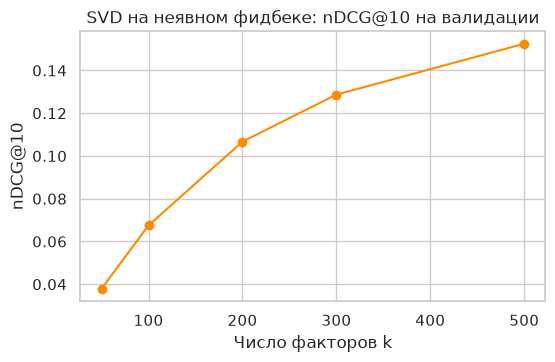

,nDCG@10,Recall@10,Coverage@10
k,,,
50,0.0379,0.0458,0.1750
100,0.0675,0.0862,0.2845
200,0.1067,0.1376,0.4197
300,0.1287,0.1669,0.5088
500,0.1525,0.1979,0.6133


In [21]:
rows = []
for k in [50, 100, 200, 300, 500]:
    m = SVDRecommender(k=k, implicit=True).fit(R_in)
    res = evaluate_topn(m, R_in, val, ks=(10,), users=val_users)
    rows.append({"k": k, "nDCG@10": res["nDCG@10"], "Recall@10": res["Recall@10"], "Coverage@10": res["Coverage@10"]})
    del m
svd_imp_tuning = pd.DataFrame(rows).set_index("k").round(4)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(svd_imp_tuning.index, svd_imp_tuning["nDCG@10"], "o-", color="darkorange")
ax.set(title="SVD на неявном фидбеке: nDCG@10 на валидации", xlabel="Число факторов k", ylabel="nDCG@10")
plt.show()
svd_imp_tuning

In [22]:
best_k_imp = int(svd_imp_tuning["nDCG@10"].idxmax())
svd_imp = SVDRecommender(k=best_k_imp, implicit=True).fit(R_train)
show_user(svd_imp, uid, N=5, name=f"SVD неявный (k={best_k_imp})")

Пользователь 33716: что понравилось в train


,book_id,title,authors,rating
57,1,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,5
137,2,"Harry Potter and the Sorcerer's Stone (Harry Potter, #1)","J.K. Rowling, Mary GrandPré",5
2607,33,Memoirs of a Geisha,Arthur Golden,5
2467,31,The Help,Kathryn Stockett,5
854,11,The Kite Runner,Khaled Hosseini,5


Рекомендации: SVD неявный (k=500)


,book_id,title,authors
0,60,The Curious Incident of the Dog in the Night-Time,Mark Haddon
1,198,The Color Purple,Alice Walker
2,48,Fahrenheit 451,Ray Bradbury
3,4,To Kill a Mockingbird,Harper Lee
4,93,The Secret Garden,Frances Hodgson Burnett


## 5. Метрики и сравнение

Релевантные книги: в тесте с оценкой от 4. Рекомендую из всего каталога, кроме того, что пользователь уже оценил в train. nDCG считаю бинарный.

Сначала проверка на маленьком примере и сравнение векторного подсчёта с обычным циклом.

In [23]:
relevant = {10, 30, 99}
for rec in ([10, 20, 30, 40, 50], [20, 40, 50, 10, 30]):
    print(rec, f"P@5={precision_at_k(rec, relevant, 5):.3f}  R@5={recall_at_k(rec, relevant, 5):.3f}  "
               f"nDCG@5={ndcg_at_k(rec, relevant, 5):.3f}")

[10, 20, 30, 40, 50] P@5=0.400  R@5=0.667  nDCG@5=0.704
[20, 40, 50, 10, 30] P@5=0.400  R@5=0.667  nDCG@5=0.384


Precision и Recall одинаковые, а nDCG падает, когда нужные книги стоят в конце списка.

In [24]:
check_users = test_users[:300]
loop = {"Precision@10": [], "Recall@10": [], "nDCG@10": []}
for u in check_users:
    rec = item_cf.get_recommendations(u + 1, N=10)
    rel = test.loc[(test["user_id"] == u + 1) & (test["rating"] >= 4), "book_id"].tolist()
    loop["Precision@10"].append(precision_at_k(rec, rel, 10))
    loop["Recall@10"].append(recall_at_k(rec, rel, 10))
    loop["nDCG@10"].append(ndcg_at_k(rec, rel, 10))
vec = evaluate_topn(item_cf, R_train, test, ks=(10,), users=check_users)
pd.DataFrame({"цикл": {k: np.mean(v) for k, v in loop.items()},
              "векторно": {k: vec[k] for k in loop}}).round(6)

,цикл,векторно
Precision@10,0.055667,0.055667
Recall@10,0.145064,0.145064
nDCG@10,0.133163,0.133163


### Сводная таблица на тесте

In [25]:
models = {
    "Popularity": pop,
    "Content (TF-IDF)": content,
    f"Item-based CF (k={best_k_icf})": item_cf,
    f"SVD явные оценки (k={best_k_svd})": svd_exp,
    f"SVD неявный (k={best_k_imp})": svd_imp,
}
results = {name: evaluate_topn(m, R_train, test, ks=(5, 10, 20), users=test_users) for name, m in models.items()}

cols = [f"{m}@{k}" for k in (5, 10, 20) for m in ("Precision", "Recall", "nDCG")] + ["Coverage@10"]
summary = pd.DataFrame(results).T[cols]
summary["RMSE"] = [np.nan, np.nan, rmse_table.iloc[3, 0], rmse_table.iloc[4, 0], np.nan]
summary.round(4)

,Precision@5,Recall@5,nDCG@5,Precision@10,Recall@10,nDCG@10,Precision@20,Recall@20,nDCG@20,Coverage@10,RMSE
Popularity,0.0004,0.0006,0.0006,0.0005,0.0015,0.0009,0.0005,0.0027,0.0014,0.0017,NaN
Content (TF-IDF),0.0512,0.0931,0.0878,0.0388,0.1328,0.1000,0.0282,0.1831,0.1159,0.8749,NaN
Item-based CF (k=20),0.1186,0.1805,0.1952,0.0834,0.2366,0.2061,0.0559,0.2967,0.2244,0.9637,0.8812
SVD явные оценки (k=200),0.0202,0.0174,0.0259,0.0143,0.0253,0.0253,0.0097,0.0351,0.0274,0.3671,0.8581
SVD неявный (k=500),0.1146,0.1573,0.1769,0.0825,0.2154,0.1876,0.0565,0.2856,0.2083,0.7501,NaN


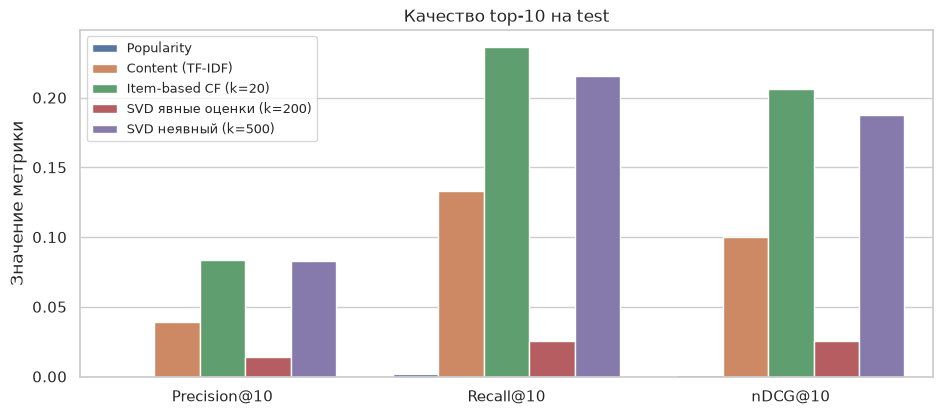

In [26]:
plot_df = summary[["Precision@10", "Recall@10", "nDCG@10"]].reset_index(names="модель").melt(
    id_vars="модель", var_name="метрика", value_name="значение")
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(data=plot_df, x="метрика", y="значение", hue="модель", ax=ax)
ax.set(title="Качество top-10 на test", xlabel="", ylabel="Значение метрики")
ax.legend(loc="upper left", fontsize=9)
plt.show()

Ещё посмотрел, как меняется качество в зависимости от того, сколько оценок у пользователя в train.

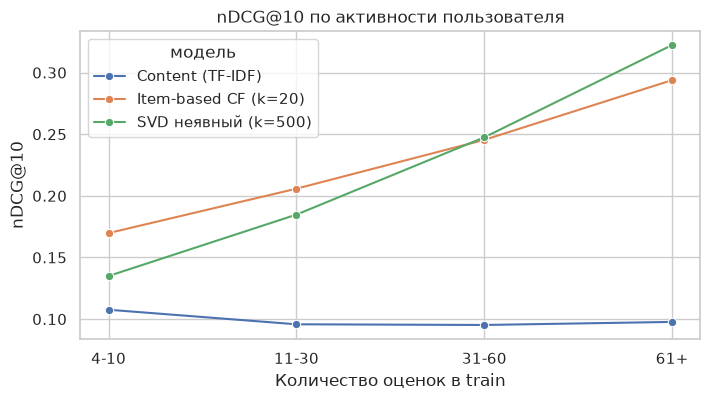

модель,Content (TF-IDF),Item-based CF (k=20),SVD неявный (k=500)
оценок в train,,,
4-10,0.1076,0.1698,0.1350
11-30,0.0958,0.2058,0.1848
31-60,0.0952,0.2454,0.2475
61+,0.0977,0.2939,0.3224


In [27]:
hist_len = np.diff(R_train.indptr)[test_users]
bins = pd.cut(hist_len, [0, 10, 30, 60, 1000], labels=["4-10", "11-30", "31-60", "61+"])
seg_rows = []
for seg in bins.categories:
    us = test_users[np.asarray(bins == seg)]
    for name in ["Content (TF-IDF)", f"Item-based CF (k={best_k_icf})", f"SVD неявный (k={best_k_imp})"]:
        res = evaluate_topn(models[name], R_train, test, ks=(10,), users=us)
        seg_rows.append({"оценок в train": seg, "модель": name, "nDCG@10": res["nDCG@10"], "пользователей": len(us)})
seg_df = pd.DataFrame(seg_rows)
seg_df["оценок в train"] = pd.Categorical(seg_df["оценок в train"], categories=bins.categories, ordered=True)

fig, ax = plt.subplots(figsize=(8, 4))
sns.lineplot(data=seg_df, x="оценок в train", y="nDCG@10", hue="модель", marker="o", ax=ax)
ax.set(title="nDCG@10 по активности пользователя", xlabel="Количество оценок в train", ylabel="nDCG@10")
plt.show()
seg_df.pivot(index="оценок в train", columns="модель", values="nDCG@10").round(4)

С ростом истории обе CF-модели заметно растут, контентная почти не меняется. SVD догоняет Item-CF где-то с 30 оценок, а у самых активных обгоняет. На короткой истории он слабее.

## 6. Гибрид

Схема такая. Если у пользователя нет ни одной понравившейся книги, показываю популярное. Если книга новая и оценок у неё нет, CF и SVD её не видят, поэтому для неё беру контентную оценку с весом beta. Для остальных книг Item-CF плюс немного контента с весом gamma. Перед смешиванием делю скоры каждой модели на максимум по пользователю, иначе шкалы разные. Gamma подобрал на валидации.

In [28]:
icf_in = ItemBasedCF(k=best_k_icf).fit(R_in)
content_in = ContentRecommender(top_tags=20).fit(books, clean_tags, R_in)
pop_in = PopularityRecommender(min_ratings=50).fit(R_in)

rows = []
for gamma in [0.0, 0.1, 0.2, 0.3, 0.5]:
    h = HybridRecommender(icf_in, content_in, pop_in, beta=0.3, gamma=gamma).fit(R_in)
    res = evaluate_topn(h, R_in, val, ks=(10,), users=val_users)
    rows.append({"gamma": gamma, "nDCG@10": res["nDCG@10"], "Recall@10": res["Recall@10"]})
gamma_tuning = pd.DataFrame(rows).set_index("gamma").round(4)
gamma_tuning

,nDCG@10,Recall@10
gamma,,
0.0,0.1704,0.2141
0.1,0.1718,0.2167
0.2,0.1728,0.2188
0.3,0.1732,0.2199
0.5,0.1726,0.2177


In [29]:
best_gamma = float(gamma_tuning["nDCG@10"].idxmax())
hybrid = HybridRecommender(item_cf, content, pop, beta=0.3, gamma=best_gamma).fit(R_train)
results[f"Hybrid (CF + {best_gamma}·Content)"] = evaluate_topn(hybrid, R_train, test, ks=(5, 10, 20), users=test_users)

final = pd.DataFrame(results).T[cols]
final["RMSE"] = summary["RMSE"]
final = final.sort_values("nDCG@10", ascending=False)
final.round(4)

,Precision@5,Recall@5,nDCG@5,Precision@10,Recall@10,nDCG@10,Precision@20,Recall@20,nDCG@20,Coverage@10,RMSE
Hybrid (CF + 0.3·Content),0.1193,0.1818,0.1967,0.0839,0.2396,0.2080,0.0559,0.3016,0.2265,0.9676,NaN
Item-based CF (k=20),0.1186,0.1805,0.1952,0.0834,0.2366,0.2061,0.0559,0.2967,0.2244,0.9637,0.8812
SVD неявный (k=500),0.1146,0.1573,0.1769,0.0825,0.2154,0.1876,0.0565,0.2856,0.2083,0.7501,NaN
Content (TF-IDF),0.0512,0.0931,0.0878,0.0388,0.1328,0.1000,0.0282,0.1831,0.1159,0.8749,NaN
SVD явные оценки (k=200),0.0202,0.0174,0.0259,0.0143,0.0253,0.0253,0.0097,0.0351,0.0274,0.3671,0.8581
Popularity,0.0004,0.0006,0.0006,0.0005,0.0015,0.0009,0.0005,0.0027,0.0014,0.0017,NaN


### Новые книги

Новых книг в данных нет, у каждой минимум 8 оценок. Поэтому взял случайные 10% книг и удалил их оценки из train, как будто книги только появились. Смотрю общее качество и отдельно качество только по этим книгам при разных beta.

In [30]:
new_books = rng.choice(n_items, n_items // 10, replace=False) + 1
R_cold = to_csr(train[~train["book_id"].isin(new_books)], n_users, n_items)
test_new = test[test["book_id"].isin(new_books)]
users_new = np.unique(test_new.loc[test_new["rating"] >= 4, "user_id"].values - 1)
users_all = rng.choice(test_users, 5000, replace=False)

icf_cold = ItemBasedCF(k=best_k_icf).fit(R_cold)
content_cold = ContentRecommender(top_tags=20).fit(books, clean_tags, R_cold)
pop_cold = PopularityRecommender(min_ratings=50).fit(R_cold)
svd_cold = SVDRecommender(k=best_k_imp, implicit=True).fit(R_cold)

cold_models = {"Item-based CF": icf_cold, "SVD неявный": svd_cold, "Content (TF-IDF)": content_cold}
for beta in [0.1, 0.3, 0.5, 0.7, 1.0]:
    cold_models[f"Hybrid β={beta}"] = HybridRecommender(icf_cold, content_cold, pop_cold,
                                                        beta=beta, gamma=best_gamma).fit(R_cold)
rows = []
for name, m in cold_models.items():
    a = evaluate_topn(m, R_cold, test, ks=(10,), users=users_all)
    n = evaluate_topn(m, R_cold, test_new, ks=(10,), users=users_new)
    rows.append({"модель": name, "nDCG@10 (все книги)": a["nDCG@10"],
                 "Recall@10 (новые книги)": n["Recall@10"], "nDCG@10 (новые книги)": n["nDCG@10"]})
cold_df = pd.DataFrame(rows).set_index("модель").round(4)
cold_df

,nDCG@10 (все книги),Recall@10 (новые книги),nDCG@10 (новые книги)
модель,,,
Item-based CF,0.1803,0.0000,0.0000
SVD неявный,0.1683,0.0000,0.0000
Content (TF-IDF),0.0904,0.1137,0.0656
Hybrid β=0.1,0.1826,0.0000,0.0000
Hybrid β=0.3,0.1840,0.0257,0.0102
Hybrid β=0.5,0.1832,0.1006,0.0403
Hybrid β=0.7,0.1738,0.1693,0.0719
Hybrid β=1.0,0.1529,0.2384,0.1134


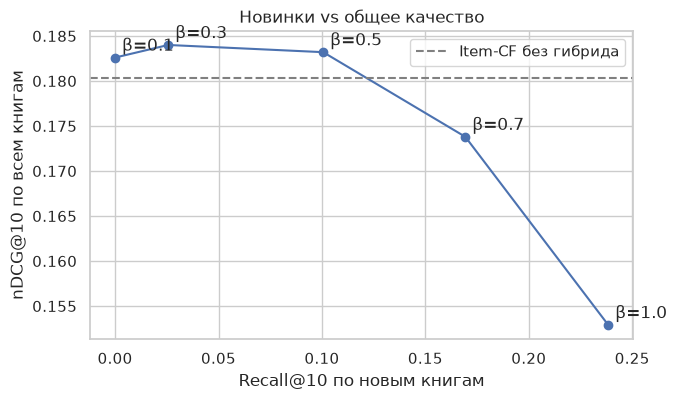

In [31]:
hyb = cold_df[cold_df.index.str.startswith("Hybrid")]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(hyb["Recall@10 (новые книги)"], hyb["nDCG@10 (все книги)"], "o-")
for name, row in hyb.iterrows():
    ax.annotate(name.replace("Hybrid ", ""), (row["Recall@10 (новые книги)"], row["nDCG@10 (все книги)"]),
                textcoords="offset points", xytext=(5, 5))
ax.axhline(cold_df.loc["Item-based CF", "nDCG@10 (все книги)"], color="gray", ls="--", label="Item-CF без гибрида")
ax.set(title="Новинки vs общее качество", xlabel="Recall@10 по новым книгам", ylabel="nDCG@10 по всем книгам")
ax.legend()
plt.show()

CF и SVD новые книги не рекомендуют вообще. Гибрид начинает их показывать. При beta 0.3-0.5 общее качество даже чуть выше, чем у чистого CF, а при 0.7 и больше новинки уже вытесняют нормальные рекомендации. Я бы остановился на 0.5.

In [32]:
# пользователь без понравившихся книг, гибрид отдаёт популярное
cold_user = int(np.flatnonzero(np.asarray((R_train >= 4).sum(axis=1)).ravel() == 0)[0]) + 1
print(f"Пользователь {cold_user}: оценок {R_train[cold_user - 1].nnz}, оценки {R_train[cold_user - 1].data}")
with_titles(pd.DataFrame({"book_id": hybrid.get_recommendations(cold_user, N=5)}))

Пользователь 3: оценок 2, оценки [1. 1.]


,book_id,title,authors
0,6361,There's Treasure Everywhere: A Calvin and Hobbes Collection,Bill Watterson
1,7947,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem"
2,6920,The Indispensable Calvin and Hobbes,Bill Watterson
3,5207,The Days Are Just Packed: A Calvin and Hobbes Collection,Bill Watterson
4,9806,"One Piece, Volume 38: Rocketman!! (One Piece, #38)",Eiichirō Oda


## Выводы

Лучшая модель в топ-N гибрид CF + контент (nDCG@10 ≈ 0.21), чистый Item-CF почти так же. Основной сигнал здесь совместное чтение: серии, авторы. SVD на неявном фидбеке близко (0.19), лучше на активных пользователях. SVD по оценкам лучший по RMSE, но в топ-N слабый. Популярное почти ноль из-за того, как собран датасет.

Плюсы и минусы коротко. Popularity: работает без истории, но не персональная. Content: справляется с новыми книгами, но советует ту же серию. Item-CF: лучший по ранжированию и объяснимый, но не видит новые книги. SVD: компактный, но тоже без новых книг, и по оценкам плохо ранжирует. Гибрид: закрывает холодный старт, но веса надо подбирать.

Что улучшить: популярность по числу оценок или to_read, to_read как ещё один сигнал, авторы и синонимы тегов в контенте, Word2Vec или BERT по описаниям, ALS или SVD++, веса гибрида по активности пользователя, признаки пользователей и нейросетевые модели, разбиение по времени на новой версии датасета.